In [205]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [206]:
X_test = pd.read_csv(r'E:\Imarticus_ Learning\Jobs - 2026\Models\data\Processed\X_test.csv')
X_train = pd.read_csv(r'E:\Imarticus_ Learning\Jobs - 2026\Models\data\Processed\X_train.csv')
y_test = pd.read_csv(r'E:\Imarticus_ Learning\Jobs - 2026\Models\data\Processed\y_test.csv')
y_train = pd.read_csv(r'E:\Imarticus_ Learning\Jobs - 2026\Models\data\Processed\y_train.csv')

X_test = X_test.drop(columns = ['Country'])
X_train = X_train.drop(columns = ['Country'])

In [207]:
print(f"Training Set   : {X_train.shape}, {y_train.shape}")
print(f"Test Set       : {X_test.shape}, {y_test.shape}")

Training Set   : (2342, 16), (2342, 1)
Test Set       : (586, 16), (586, 1)


In [219]:
X_train.describe()

,Year,Status,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,Polio,Total expenditure,Diphtheria,HIV/AIDS,thinness 5-9 years,Schooling,Hepatitis B_missing
count,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000,2342.000
mean,0.000,0.827,0.000,0.000,0.000,-0.000,-0.264,-0.000,0.000,-0.322,-0.000,-0.281,0.451,0.000,0.000,0.190
std,1.000,0.378,1.000,1.000,1.000,1.000,0.841,1.000,1.000,0.694,1.000,0.707,0.637,1.000,1.000,0.392
min,-1.640,0.000,-3.954,-1.214,-1.214,-1.477,-2.240,-1.026,-1.837,-1.896,-2.295,-1.883,0.000,-2.021,-3.663,0.000
25%,-0.771,1.000,-0.416,-1.214,-0.889,-0.797,-0.606,-1.026,-0.935,-0.767,-0.629,-0.713,0.000,-0.774,-0.563,0.000
50%,0.098,1.000,0.234,-0.065,-0.219,0.071,0.000,-0.141,0.217,0.000,-0.063,0.000,0.000,-0.039,0.075,0.000
75%,0.966,1.000,0.673,0.940,0.772,0.765,0.394,0.776,0.905,0.233,0.558,0.287,1.000,0.822,0.675,0.000
max,1.618,1.000,1.789,2.204,3.324,2.169,0.652,2.731,1.982,0.356,4.881,0.409,1.667,2.464,2.628,1.000


In [209]:
X_train.columns

Index(['Year', 'Status', 'Adult Mortality', 'infant deaths', 'Alcohol',
       'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'Polio',
       'Total expenditure', 'Diphtheria ', ' HIV/AIDS', ' thinness 5-9 years',
       'Schooling', 'Hepatitis B_missing'],
      dtype='object')

In [210]:
# Transformations for Linear Regression
# Log1p Transformations
log_cols = ['Adult Mortality', 'percentage expenditure', 'Measles ']  
yeo_john_cols = [' thinness 5-9 years', 'infant deaths', 'Polio', 'Diphtheria ', ' HIV/AIDS', 'Hepatitis B'] 
for i in log_cols:
    X_train[i] = np.log1p(X_train[i])
    X_test[i] = np.log1p(X_test[i])
    print(f"Successful log1p transformation of {i}")

for i in yeo_john_cols:
    pt = PowerTransformer(method='yeo-johnson', standardize = False)
    X_train[[i]] = pt.fit_transform(X_train[[i]])
    X_test[[i]] = pt.transform(X_test[[i]])
    print(f"Successful Yeo-Johnson transformation of {i}")

Successful log1p transformation of Adult Mortality
Successful log1p transformation of percentage expenditure
Successful log1p transformation of Measles 
Successful Yeo-Johnson transformation of  thinness 5-9 years
Successful Yeo-Johnson transformation of infant deaths
Successful Yeo-Johnson transformation of Polio
Successful Yeo-Johnson transformation of Diphtheria 
Successful Yeo-Johnson transformation of  HIV/AIDS
Successful Yeo-Johnson transformation of Hepatitis B


In [211]:
# Check remaining untransformed columns for skew
for col in ['Alcohol', ' BMI ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'Schooling']:
    print(col, X_train[col].skew())

Alcohol 0.5762473994261988
 BMI  -0.18680104920409119
Polio -0.9850990127078939
Total expenditure 0.6670005907506374
Diphtheria  -1.034820471533926
 HIV/AIDS 0.9499776998850028
Schooling -0.5460443460798733


In [212]:
# Scaling
# NOTE: Year, Status, Hepatitis B_missing (categorical/binary)
# NOTE: the yeo_john_cols — already standardized via standardize=True
# NOTE: After Normalization there are skew so we use robust scalr for thosed skewd columns
standard_cols = ['Alcohol', ' BMI ', 'Total expenditure', 'Schooling',
                  'Adult Mortality', 'percentage expenditure', 'Measles ',' thinness 5-9 years', 'infant deaths', 'Year']
robust_cols = ['Polio', 'Diphtheria ', ' HIV/AIDS','Hepatitis B']

ss = StandardScaler()
X_train[standard_cols] = ss.fit_transform(X_train[standard_cols])
X_test[standard_cols] = ss.transform(X_test[standard_cols])

rs = RobustScaler()
X_train[robust_cols] = rs.fit_transform(X_train[robust_cols])
X_test[robust_cols] = rs.transform(X_test[robust_cols])

In [213]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_train_pred = lr.predict(X_train)

print("R²:", r2_score(y_train, y_train_pred))
print("RMSE:", root_mean_squared_error(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))

R²: 0.8212192533448026
RMSE: 4.048722538692921
MAE: 3.0365140488742397


In [214]:
y_pred = lr.predict(X_test)

print("R²:", r2_score(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

R²: 0.8189983635778665
RMSE: 3.9568337556614748
MAE: 3.040069797576695


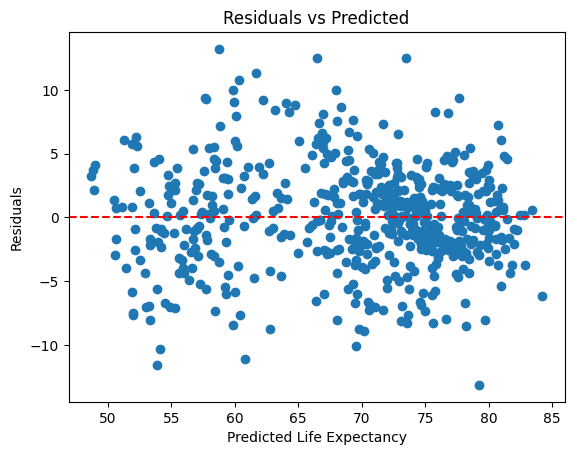

In [215]:
import matplotlib.pyplot as plt

residuals = y_test.values.flatten() - y_pred.flatten()
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Life Expectancy')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

In [216]:
# Save model
from pathlib import Path
import joblib

save_dir = Path(r'E:\Imarticus_ Learning\Jobs - 2026\Models\models')

joblib.dump(lr, save_dir / 'Basic_Linear_regression_model.pkl')

['E:\\Imarticus_ Learning\\Jobs - 2026\\Models\\models\\Basic_Linear_regression_model.pkl']

In [218]:
# Load the model 
linear_model = joblib.load(save_dir / 'Basic_Linear_regression_model.pkl')
predictions = linear_model.predict(X_test)